# Distribuzione geografica dei giocatori FC25

La mappa mostra il numero di giocatori presenti nel dataset per nazionalità. I nomi utilizzati dal dataset vengono uniformati a quelli del file geografico; le quattro nazioni calcistiche del Regno Unito sono aggregate perché il GeoJSON rappresenta un unico territorio denominato `United Kingdom`.

Il file geografico è conservato localmente nel progetto, così la costruzione della mappa non dipende da una risorsa Internet durante l'esecuzione.


In [1]:
from pathlib import Path
import json

import pandas as pd
import folium

DATA_PATH = Path('../data/raw/fc25/all_players.csv')
GEOJSON_PATH = Path('../data/raw/geografia/world-countries.json')
MAP_OUTPUT_PATH = Path('mappa_mondo_finale.html')

COUNTRY_MAP = {
    'United States': 'United States of America',
    'China PR': 'China',
    'Republic of Ireland': 'Ireland',
    'England': 'United Kingdom',
    'Scotland': 'United Kingdom',
    'Wales': 'United Kingdom',
    'Northern Ireland': 'United Kingdom',
    'Holland': 'Netherlands',
    'Korea Republic': 'South Korea',
    'Korea DPR': 'North Korea',
    'North Macedonia': 'Macedonia',
    'Guinea-Bissau': 'Guinea Bissau',
    'Chinese Taipei': 'Taiwan',
    'Serbia': 'Republic of Serbia',
    'Congo DR': 'Democratic Republic of the Congo',
    'Congo': 'Republic of the Congo',
    'Tanzania': 'United Republic of Tanzania',
    "Côte d'Ivoire": 'Ivory Coast',
}

df = pd.read_csv(DATA_PATH)
world_geojson = json.loads(GEOJSON_PATH.read_text(encoding='utf-8'))
print(f'Giocatori caricati: {len(df):,}')
print(f'Paesi presenti nel file geografico: {len(world_geojson["features"]):,}')


Giocatori caricati: 17,737
Paesi presenti nel file geografico: 177


## Uniformazione dei nomi e controllo della copertura

Prima di costruire la mappa viene controllato quanti giocatori possono essere associati a un territorio. Alcuni piccoli Stati o territori non sono presenti nel GeoJSON a bassa risoluzione: vengono elencati esplicitamente e non confluiscono in Paesi diversi.


In [2]:
df_map = df[['Name', 'Nation']].copy()
df_map['Country'] = df_map['Nation'].replace(COUNTRY_MAP)

player_counts = (
    df_map.groupby('Country', as_index=False)
    .agg(PlayerCount=('Name', 'size'))
    .sort_values('PlayerCount', ascending=False)
)

geojson_countries = {
    feature['properties']['name']
    for feature in world_geojson['features']
}
mapped_mask = player_counts['Country'].isin(geojson_countries)
mapped_counts = player_counts.loc[mapped_mask].copy()
unmapped_counts = player_counts.loc[~mapped_mask].copy()

mapped_players = int(mapped_counts['PlayerCount'].sum())
coverage = mapped_players / len(df_map) * 100

print(f'Giocatori rappresentati: {mapped_players:,} su {len(df_map):,} ({coverage:.2f}%)')
print(f'Giocatori non rappresentati: {len(df_map) - mapped_players:,}')
display(unmapped_counts.style.hide(axis='index'))


Giocatori rappresentati: 17,664 su 17,737 (99.59%)
Giocatori non rappresentati: 73


Country,PlayerCount
Cape Verde Islands,22
Curaçao,10
Grenada,8
Hong Kong,4
Malta,4
Montserrat,4
Antigua and Barbuda,3
St. Lucia,3
Palestine,3
St. Kitts and Nevis,3


## Mappa coropletica

L'intensità del colore rappresenta il numero assoluto di giocatori associati a ciascuna nazionalità. Passando il cursore su un Paese vengono mostrati il nome e il relativo conteggio.


In [3]:
count_lookup = dict(zip(mapped_counts['Country'], mapped_counts['PlayerCount']))
for feature in world_geojson['features']:
    country = feature['properties']['name']
    feature['properties']['PlayerCount'] = int(count_lookup.get(country, 0))

football_map = folium.Map(
    location=[20, 0],
    zoom_start=2,
    tiles='CartoDB positron',
)

folium.Choropleth(
    geo_data=world_geojson,
    data=mapped_counts,
    columns=['Country', 'PlayerCount'],
    key_on='feature.properties.name',
    fill_color='YlOrRd',
    fill_opacity=0.75,
    line_opacity=0.25,
    nan_fill_color='#eeeeee',
    legend_name='Numero di giocatori',
    name='Giocatori per nazionalità',
).add_to(football_map)

folium.GeoJson(
    world_geojson,
    name='Dettagli',
    style_function=lambda feature: {
        'fillOpacity': 0,
        'color': 'transparent',
        'weight': 0,
    },
    tooltip=folium.GeoJsonTooltip(
        fields=['name', 'PlayerCount'],
        aliases=['Paese:', 'Giocatori:'],
        localize=True,
        sticky=False,
    ),
).add_to(football_map)

folium.LayerControl().add_to(football_map)

legend_css = """
<style>
div.legend.leaflet-control {
    position: fixed !important;
    bottom: 20px !important;
    left: 50% !important;
    transform: translateX(-50%) !important;
    top: auto !important;
    right: auto !important;
    z-index: 9999 !important;
    background-color: rgba(255, 255, 255, 0.90) !important;
    padding: 6px !important;
    border-radius: 5px !important;
}
</style>
"""
football_map.get_root().html.add_child(folium.Element(legend_css))
football_map.save(MAP_OUTPUT_PATH)

print(f'Mappa salvata in: {MAP_OUTPUT_PATH}')
football_map


Mappa salvata in: mappa_mondo_finale.html


## Versione statica per la relazione

La stessa distribuzione viene esportata anche come immagine statica. Per rendere leggibili sia i Paesi con pochi giocatori sia quelli maggiormente rappresentati, la legenda utilizza classi di conteggio anziché una scala continua.

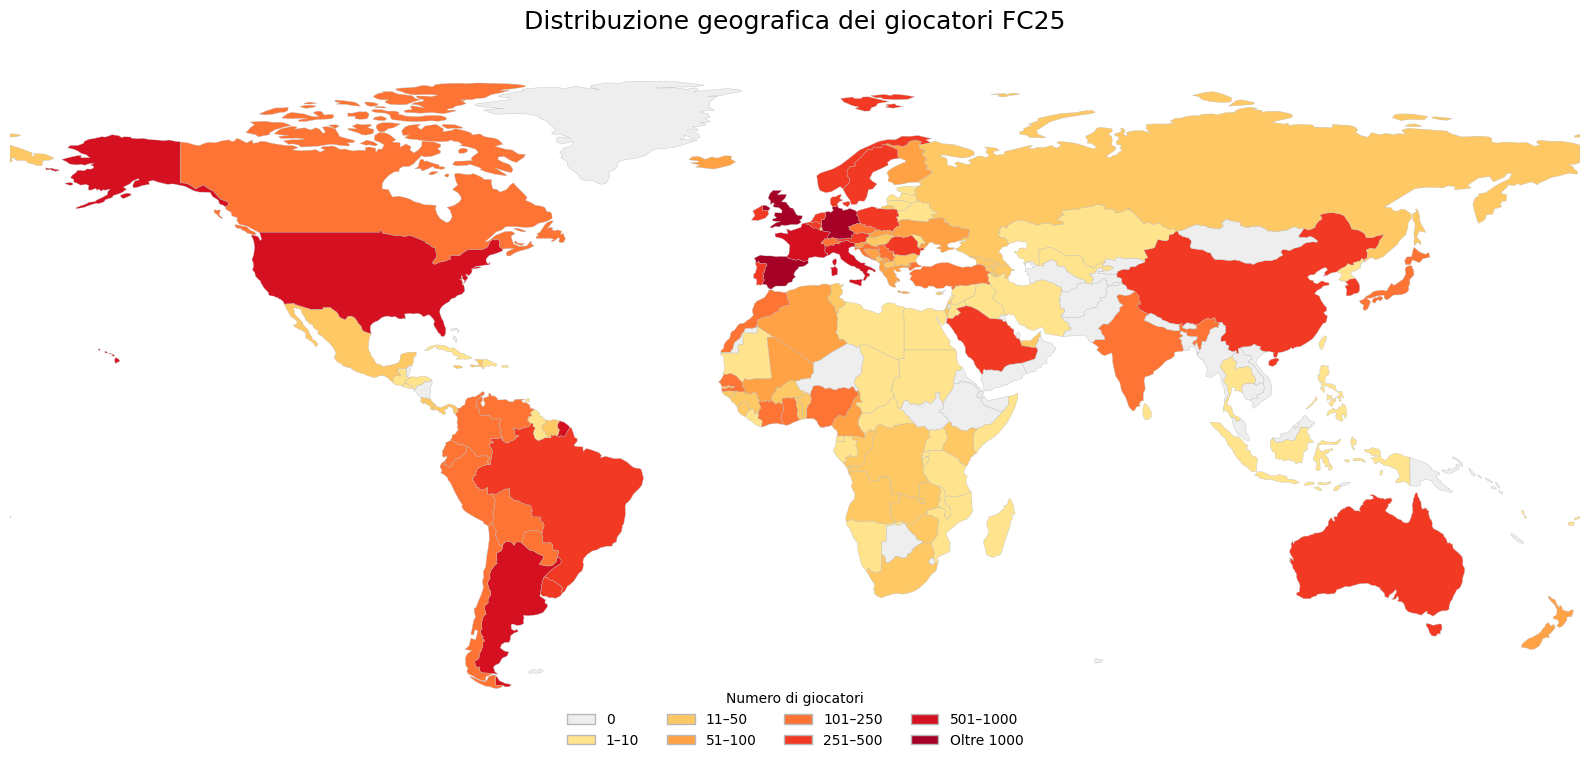

Mappa statica salvata in: figure_eda\16_mappa_mondo_giocatori.png


In [4]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import PatchCollection
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch, Polygon as MplPolygon

STATIC_MAP_OUTPUT_PATH = Path(
    'figure_eda/16_mappa_mondo_giocatori.png'
)
STATIC_MAP_OUTPUT_PATH.parent.mkdir(exist_ok=True)

count_lookup = dict(zip(mapped_counts['Country'], mapped_counts['PlayerCount']))
map_patches = []
map_values = []

for feature in world_geojson['features']:
    country = feature['properties']['name']
    geometry = feature['geometry']
    polygons = (
        [geometry['coordinates']]
        if geometry['type'] == 'Polygon'
        else geometry['coordinates']
    )

    for polygon in polygons:
        exterior_ring = np.asarray(polygon[0])
        map_patches.append(MplPolygon(exterior_ring, closed=True))
        map_values.append(int(count_lookup.get(country, 0)))

class_boundaries = [-0.5, 0.5, 10.5, 50.5, 100.5, 250.5, 500.5, 1000.5, 2500.5]
class_labels = [
    '0', '1–10', '11–50', '51–100',
    '101–250', '251–500', '501–1000', 'Oltre 1000'
]
positive_colors = plt.cm.YlOrRd(np.linspace(0.18, 0.92, 7))
map_colors = ['#eeeeee', *positive_colors]
map_cmap = ListedColormap(map_colors)
map_norm = BoundaryNorm(class_boundaries, map_cmap.N)

fig, ax = plt.subplots(figsize=(16, 9))
collection = PatchCollection(
    map_patches,
    cmap=map_cmap,
    norm=map_norm,
    edgecolor='#b8b8b8',
    linewidth=0.25,
)
collection.set_array(np.asarray(map_values))
ax.add_collection(collection)
ax.set_xlim(-180, 180)
ax.set_ylim(-60, 90)
ax.set_aspect('equal', adjustable='box')
ax.axis('off')
ax.set_title(
    'Distribuzione geografica dei giocatori FC25',
    fontsize=18, pad=18
)

legend_handles = [
    Patch(facecolor=color, edgecolor='#b8b8b8', label=label)
    for color, label in zip(map_colors, class_labels)
]
ax.legend(
    handles=legend_handles,
    title='Numero di giocatori',
    loc='lower center',
    bbox_to_anchor=(0.5, -0.08),
    ncol=4,
    frameon=False,
)

fig.tight_layout()
fig.savefig(
    STATIC_MAP_OUTPUT_PATH,
    dpi=300,
    bbox_inches='tight',
    facecolor='white',
)
plt.show()
print(f'Mappa statica salvata in: {STATIC_MAP_OUTPUT_PATH}')

## Interpretazione

La copertura supera il **99%** dei giocatori. Le esclusioni residue riguardano piccoli Stati e territori assenti dal file geografico utilizzato; sono riportate nella tabella precedente per rendere trasparente il limite della visualizzazione. La mappa descrive la rappresentazione delle nazionalità nel dataset FC25 e non la distribuzione geografica dei campionati o delle squadre.
